<a href="https://colab.research.google.com/github/tqan27/FinancialPlan/blob/main/Financial_Plan_Visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

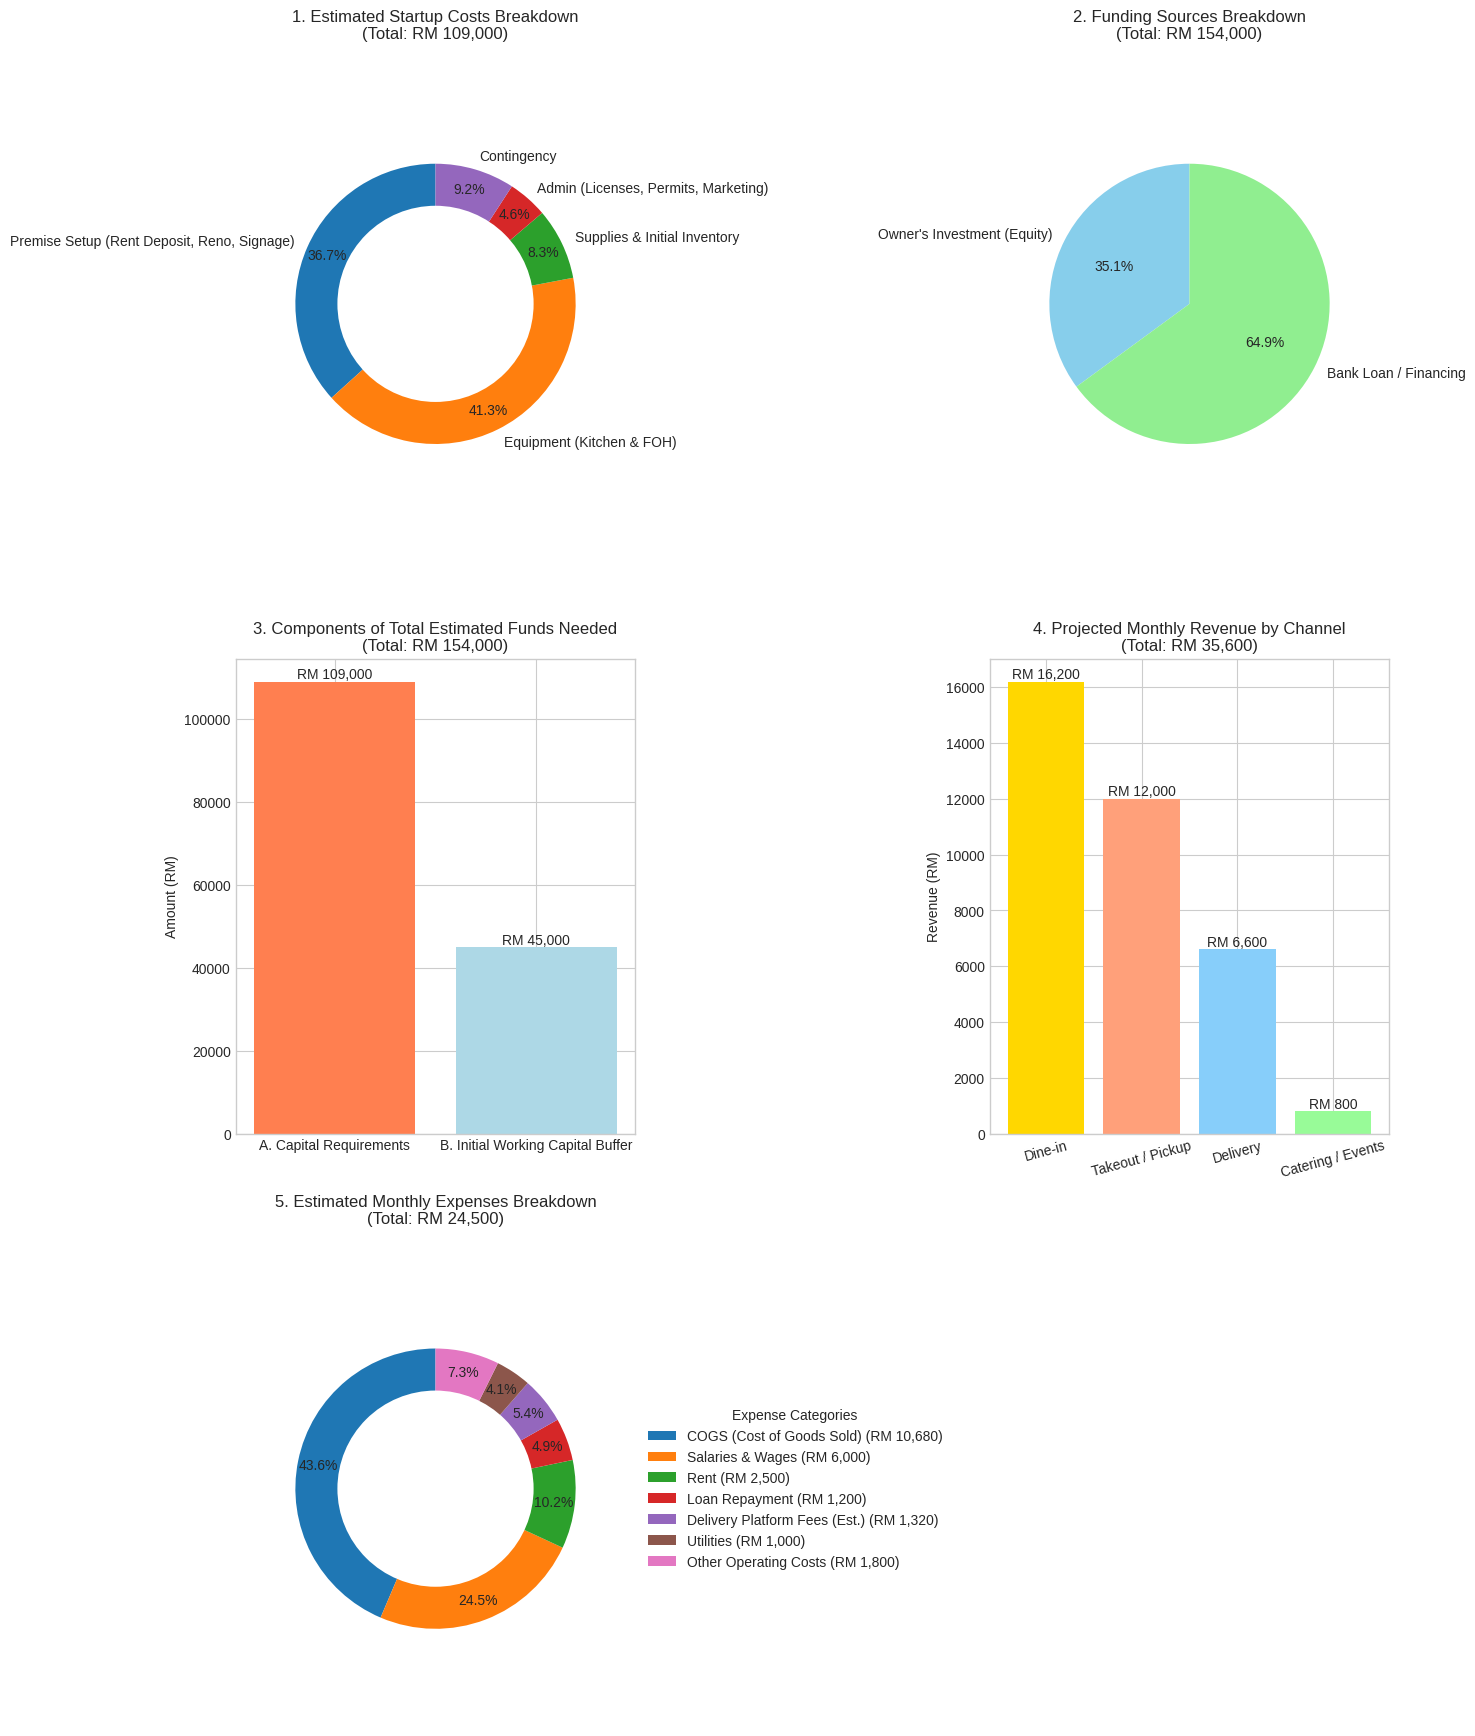

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data extracted/simplified from the financial plan document fb_financial_plan_rm_v2
# Note: Some categories are grouped for chart clarity. All values in RM.

# --- 1. Capital Requirements Data (Simplified Categories for Chart) ---
capital_labels = [
    'Premise Setup (Rent Deposit, Reno, Signage)',
    'Equipment (Kitchen & FOH)',
    'Supplies & Initial Inventory',
    'Admin (Licenses, Permits, Marketing)',
    'Contingency'
]
# Adjusted values to sum to 109,000 for illustration based on grouping
capital_values = [40000, 45000, 9000, 5000, 10000]
capital_total = sum(capital_values)

# --- 2. Funding Sources Data ---
funding_labels = ["Owner's Investment (Equity)", 'Bank Loan / Financing']
funding_values = [54000, 100000]
funding_total = sum(funding_values)

# --- 3. Total Funds Needed Data ---
funds_needed_labels = ['A. Capital Requirements', 'B. Initial Working Capital Buffer']
funds_needed_values = [109000, 45000]
total_funds_needed = sum(funds_needed_values)

# --- 4. Monthly Revenue Data ---
revenue_labels = ['Dine-in', 'Takeout / Pickup', 'Delivery', 'Catering / Events']
revenue_values = [16200, 12000, 6600, 800]
revenue_total = sum(revenue_values)

# --- 5. Monthly Expenses Data (Simplified Categories & Estimated Delivery Fees) ---
# Estimate Delivery Fees (e.g., 20% of Delivery Revenue)
delivery_revenue = 6600
delivery_fee_estimate = delivery_revenue * 0.20

expense_labels = [
    'COGS (Cost of Goods Sold)',
    'Salaries & Wages',
    'Rent',
    'Loan Repayment',
    'Delivery Platform Fees (Est.)',
    'Utilities',
    'Other Operating Costs' # (Marketing, POS, Cleaning, Insurance, Misc)
]
expense_values = [
    10680, # COGS (30% of 35600 revenue)
    6000,  # Salaries
    2500,  # Rent
    1200,  # Loan Repayment
    delivery_fee_estimate, # Estimated Delivery Fees
    1000,  # Utilities
    (500 + 300 + 300 + 200 + 500) # Marketing+POS+Cleaning+Insurance+Misc
]
expense_total = sum(expense_values)

# --- Create Plots ---
plt.style.use('seaborn-v0_8-whitegrid') # Use a clean style
fig, axs = plt.subplots(3, 2, figsize=(15, 18)) # Create a figure with multiple subplots

# --- Chart 1: Capital Requirements Breakdown (Pie Chart) ---
axs[0, 0].pie(capital_values, labels=capital_labels, autopct='%1.1f%%', startangle=90, pctdistance=0.85)
axs[0, 0].set_title(f'1. Estimated Startup Costs Breakdown\n(Total: RM {capital_total:,.0f})', pad=20)
# Draw circle for donut chart effect (optional)
centre_circle = plt.Circle((0,0),0.70,fc='white')
axs[0, 0].add_artist(centre_circle)
axs[0, 0].axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.

# --- Chart 2: Funding Sources Breakdown (Pie Chart) ---
axs[0, 1].pie(funding_values, labels=funding_labels, autopct='%1.1f%%', startangle=90, colors=['skyblue', 'lightgreen'])
axs[0, 1].set_title(f'2. Funding Sources Breakdown\n(Total: RM {funding_total:,.0f})', pad=20)
axs[0, 1].axis('equal')

# --- Chart 3: Total Funds Needed Components (Bar Chart) ---
bars3 = axs[1, 0].bar(funds_needed_labels, funds_needed_values, color=['coral', 'lightblue'])
axs[1, 0].set_title(f'3. Components of Total Estimated Funds Needed\n(Total: RM {total_funds_needed:,.0f})')
axs[1, 0].set_ylabel('Amount (RM)')
# Add values on top of bars
for bar in bars3:
    yval = bar.get_height()
    axs[1, 0].text(bar.get_x() + bar.get_width()/2.0, yval, f'RM {yval:,.0f}', va='bottom', ha='center') # Add text labels

# --- Chart 4: Monthly Revenue by Channel (Bar Chart) ---
bars4 = axs[1, 1].bar(revenue_labels, revenue_values, color=['gold', 'lightsalmon', 'lightskyblue', 'palegreen'])
axs[1, 1].set_title(f'4. Projected Monthly Revenue by Channel\n(Total: RM {revenue_total:,.0f})')
axs[1, 1].set_ylabel('Revenue (RM)')
axs[1, 1].tick_params(axis='x', rotation=15) # Rotate x-axis labels slightly
# Add values on top of bars
for bar in bars4:
    yval = bar.get_height()
    axs[1, 1].text(bar.get_x() + bar.get_width()/2.0, yval, f'RM {yval:,.0f}', va='bottom', ha='center') # Add text labels


# --- Chart 5: Monthly Expenses Breakdown (Pie Chart) ---
# Filter out very small slices for better labeling if needed, or adjust text positions
patches, texts, autotexts = axs[2, 0].pie(expense_values, autopct='%1.1f%%', startangle=90, pctdistance=0.85)
axs[2, 0].set_title(f'5. Estimated Monthly Expenses Breakdown\n(Total: RM {expense_total:,.0f})', pad=20)
# Add legend outside the pie chart
axs[2, 0].legend(patches, [f'{l} (RM {v:,.0f})' for l, v in zip(expense_labels, expense_values)],
                 title="Expense Categories", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
# Draw circle for donut chart effect (optional)
centre_circle_exp = plt.Circle((0,0),0.70,fc='white')
axs[2, 0].add_artist(centre_circle_exp)
axs[2, 0].axis('equal')

# Hide the empty subplot (bottom right)
axs[2, 1].axis('off')

# --- Final Adjustments & Display ---
plt.tight_layout(pad=3.0) # Adjust layout to prevent overlap
plt.show()